# Code

In [1]:
# Importing Packages


import numpy as np
from collections import defaultdict
import time
import math
from numba import njit
import matplotlib.pyplot as plt
from sklearn.neighbors import KDTree
from scipy.spatial import distance
from matplotlib.pyplot import cm



# LSH Datastructure for L1

# Tree class
class TreeNode:
    def __init__(self):
        self.children = []

    def set_cluster(self, cluster):
        self.cluster = cluster

    def add_child(self, child):
        self.children.append(child)



# Quadtree auxiliary functions
@njit
def find_bounds(edge, lower, midpoint, upper, dimension):
    sub_lower = np.zeros(dimension)
    sub_upper = np.zeros(dimension)

    for d in range(dimension):
        if edge[d]:
            sub_lower[d] = lower[d]
            sub_upper[d] = midpoint[d]
        else:
            sub_lower[d] = midpoint[d]
            sub_upper[d] = upper[d]
    return sub_lower, sub_upper


@njit
def compute_shift(dimension, lower, upper):
    shift = np.zeros(dimension)
    for d in range(dimension):
        spread = upper[d] - lower[d]
        shift[d] = np.random.uniform(0, spread)
        upper[d] += spread
    return shift, upper


# Meta quadtree function
def build_quadtree(dataset, max_levels=0, random_shift=False):
    "If max_levels=0 there no level limit, quadtree will partition until all clusters are singletons"
    dimension = dataset.shape[1]
    lower = np.amin(dataset, axis=0)
    upper = np.amax(dataset, axis=0)
    
    # Randomly shift dataset
    shift = np.zeros(dimension)
    if random_shift:
        shift, upper = compute_shift(dimension, lower, upper)
    dataset_shifted = dataset + shift

    if dimension <= 3:
        return build_quadtree_aux_small_d(dataset_shifted, np.arange(dataset.shape[0]), lower, upper, max_levels)
    else:
        return build_quadtree_aux(dataset_shifted, np.arange(dataset.shape[0]), lower, upper, max_levels)


def build_quadtree_aux_small_d(dataset, cluster, lower, upper, max_levels):
    """
    "lower" is the "bottom-left" (in all dimensions) corner of current hypercube
    "upper" is the "upper-right" (in all dimensions) corner of current hypercube
    """
    dimension = dataset.shape[1]

    node = TreeNode()
    if max_levels == 1 or len(cluster) <= 1:
        # Leaf
        node.set_cluster(cluster)
        return node

    # Non-leaf
    
    # Get midpoint of current cell
    midpoint = 0.5 * (lower + upper)
    
    # Determine which subcell all points fall into. 
    # For small d, we can explicitly write out the small cell id in binary
    bool_dataset = dataset[cluster, :] <= midpoint
    map_to_cells = bool_dataset.dot(np.array([2**k for k in range(dimension)]))
    sort_map_to_cells = np.argsort(map_to_cells)
    map_to_cells_sorted = map_to_cells[sort_map_to_cells]
    
    # Group points by subcells they fall in
    unq_first = np.concatenate(([True], map_to_cells_sorted[1:] != map_to_cells_sorted[:-1]))
    unq_items = map_to_cells_sorted[unq_first]
    unq_count = np.diff(np.nonzero(unq_first)[0])
    
    # unq_idx contains the points grouped by subcells, unq_items contains the id of the cell (number between 1 and 2^d)
    unq_idx = np.split(sort_map_to_cells, np.cumsum(unq_count))

    # We recurse over each non-empty subcell
    for i, subcluster in enumerate(unq_idx):
        cell_number = unq_items[i]
        edge = np.array([int(x) for x in list(('{0:0' + str(dimension) + 'b}').format(cell_number))][::-1])
        sub_lower, sub_upper = find_bounds(edge, lower, midpoint, upper, dimension)
        node.add_child(build_quadtree_aux_small_d(dataset, cluster[subcluster], sub_lower, sub_upper, max_levels - 1))
    return node



def build_quadtree_aux(dataset, cluster, lower, upper, max_levels):
    """
    "lower" is the "bottom-left" (in all dimensions) corner of current hypercube
    "upper" is the "upper-right" (in all dimensions) corner of current hypercube
    """
    dimension = dataset.shape[1]

    node = TreeNode()
    if max_levels == 1 or len(cluster) <= 1:
        # Leaf
        node.set_cluster(cluster)
        return node

    # Non-leaf
    
    # Get midpoint of cell
    midpoint = 0.5 * (lower + upper)
    
    # Hash all points to subcells (only loop over non-empty ones!)
    subclusters = defaultdict(list)
    for i in cluster:
        # Figure out which of the 2^d cells your point lands on by hashing
        subclusters[tuple(dataset[i, :] <= midpoint)].append(i)

    # Loop over non empty sub cells
    for edge, subcluster in subclusters.items():
        sub_lower, sub_upper = find_bounds(edge, lower, midpoint, upper, dimension)
        node.add_child(build_quadtree_aux(dataset, subcluster, sub_lower, sub_upper, max_levels - 1))
    return node

    

def depth_first_search(start):
    dfs_order = []
    stack = [start]
    visited = set()
    while stack:
        vertex = stack.pop()
        if vertex in visited:
            continue
        visited.add(vertex)
        if not vertex.children:
            dfs_order.extend(vertex.cluster)
        for neighbor in vertex.children:
            stack.append(neighbor)
    return dfs_order



# Computes CH(A,B) + CH(B,A)
# affiliation array 0 for A, 1 for B
# assume points of A are before points of B

def approx_chamfer_estimates(dataset, affiliation_array, max_levels, p=1):

    members_of_A = np.where(affiliation_array == 0)[0]
    members_of_B = np.where(affiliation_array == 1)[0]

    tree = build_quadtree(dataset, max_levels=max_levels)
    n, d = dataset.shape

    # Run a dfs on the quadtree
    dfs_order = depth_first_search(tree)
    dfs_order = np.array(dfs_order)
    dfs_order_argsort = np.argsort(dfs_order)


    # Compute distances from A to B
    
    marked_dfs_order = np.ones(n, dtype=np.int64)
    marked_dfs_order[dfs_order_argsort[members_of_A]] = 0
    old_val = marked_dfs_order[0]
    marked_dfs_order_loc_non_zero = np.where(marked_dfs_order == 1)[0]
    marked_dfs_order[marked_dfs_order_loc_non_zero] = marked_dfs_order_loc_non_zero
    marked_dfs_order[0] = dfs_order_argsort[members_of_B].min()
    
    # Get left and right neighbors B of A in dfs order

    left_B_neighbors = dfs_order[np.maximum.accumulate(marked_dfs_order)]
    marked_dfs_order[0] = old_val
    marked_dfs_order[dfs_order_argsort[members_of_A]] = dfs_order_argsort[members_of_B].max()
    right_B_neighbors = dfs_order[np.minimum.accumulate(marked_dfs_order[::-1])[::-1]]
    
    chamfer_A_to_B = np.minimum(np.linalg.norm(dataset[members_of_A, : ] - dataset[left_B_neighbors[dfs_order_argsort[members_of_A]], :], axis=1, ord=p), np.linalg.norm(dataset[members_of_A, : ] - dataset[right_B_neighbors[dfs_order_argsort[members_of_A]], :], axis=1, ord=p))

    # Compute distances from B to A
    marked_dfs_order = np.ones(n, dtype=np.int64)
    marked_dfs_order[dfs_order_argsort[members_of_B]] = 0
    old_val = marked_dfs_order[0]
    marked_dfs_order_loc_non_zero = np.where(marked_dfs_order == 1)[0]
    marked_dfs_order[marked_dfs_order_loc_non_zero] = marked_dfs_order_loc_non_zero
    marked_dfs_order[0] = dfs_order_argsort[members_of_A].min()
    
    # Get left and right neighbors A of B in dfs order

    left_A_neighbors = dfs_order[np.maximum.accumulate(marked_dfs_order)]
    marked_dfs_order[0] = old_val
    marked_dfs_order[dfs_order_argsort[members_of_B]] = dfs_order_argsort[members_of_A].max()
    right_A_neighbors = dfs_order[np.minimum.accumulate(marked_dfs_order[::-1])[::-1]]

    chamfer_B_to_A = np.minimum(np.linalg.norm(dataset[members_of_B, : ] - dataset[left_A_neighbors[dfs_order_argsort[members_of_B]], :], axis=1, ord=p), np.linalg.norm(dataset[members_of_B, : ] - dataset[right_A_neighbors[dfs_order_argsort[members_of_B]], :], axis=1, ord=p))

    return np.hstack((chamfer_A_to_B, chamfer_B_to_A))

def importance_sampling(dataset_A, dataset_B, prob_A, prob_B, trials, dist='1'):
    if dist == '1':
        dist='cityblock'
    idx_sampled_A = np.random.choice(dataset_A.shape[0], size=trials, p = prob_A)
    idx_sampled_B = np.random.choice(dataset_B.shape[0], size=trials, p = prob_B)
    output_A = (distance.cdist(dataset_A[idx_sampled_A,:], dataset_B, metric=dist).min(axis=1)/prob_A[idx_sampled_A]).sum()/trials
    output_B = (distance.cdist(dataset_B[idx_sampled_B,:], dataset_A, metric=dist).min(axis=1)/prob_B[idx_sampled_B]).sum()/trials
    return output_A + output_B

# ShapeNet

In [47]:
# samples L1 plot
samples = range(1,51)
samples_approx = np.zeros((50, len(samples)))
uniform_approx = np.zeros((50, len(samples)))
ids = np.random.randint(len(files), size=2)
dataset_A = np.load('shapenet_pc/'+'sample_shapenet_0')
dataset_B = np.load('shapenet_pc/'+'sample_shapenet_1')
n = dataset_A.shape[0]
dataset = np.vstack((dataset_A, dataset_B))
true_val = (distance.cdist(dataset_A, dataset_B, metric='cityblock').min(axis=1)).sum() + (distance.cdist(dataset_B, dataset_A, metric='cityblock').min(axis=1)).sum()
affiliation_array = np.hstack((np.zeros(n), np.ones(n)))
output = approx_chamfer_estimates(dataset, affiliation_array, 3, p=1)
prob_A = output[:n]/output[:n].sum()
prob_B = output[n:]/output[n:].sum()
for t in range(50):
    curr_importance_sampling_vals = np.zeros(len(samples))
    curr_uniform_sampling_vals = np.zeros(len(samples))
    j = 0
    for s in samples:
        curr_importance_sampling_vals[j] = importance_sampling(dataset_A, dataset_B, prob_A, prob_B, s)
        curr_uniform_sampling_vals[j] = importance_sampling(dataset_A, dataset_B, np.ones(n)/n, np.ones(n)/n, s)
        j += 1
    samples_approx[t] = np.abs(curr_importance_sampling_vals - true_val)/true_val
    uniform_approx[t] = np.abs(curr_uniform_sampling_vals - true_val)/true_val

In [126]:
print(samples_approx.mean(axis=0))
print(samples_approx.std(axis=0))
print(uniform_approx.mean(axis=0))
print(uniform_approx.std(axis=0))

[0.18370128 0.15023279 0.12517089 0.08374162 0.07397594 0.08436349
 0.07641275 0.06469971 0.05341208 0.0630189  0.05679395 0.05204722
 0.0462035  0.04585468 0.04454977 0.0531478  0.05560382 0.05568368
 0.05101955 0.04688846 0.04473587 0.03702978 0.0413303  0.03787459
 0.03736493 0.03400118 0.03841845 0.03959246 0.03554697 0.03885708
 0.03595685 0.02736387 0.03481595 0.03458574 0.03444975 0.0332238
 0.03819791 0.0320874  0.03170112 0.03467922 0.03277811 0.03325089
 0.03031537 0.02622875 0.03330845 0.02971818 0.02647304 0.03171169
 0.0250084  0.03034835]
[0.13165449 0.09214513 0.08969046 0.06272542 0.05588366 0.0737718
 0.06487627 0.04545778 0.03587036 0.04218141 0.04534828 0.04170628
 0.04152007 0.03600212 0.03600471 0.04260071 0.03555594 0.03294604
 0.03612136 0.03600298 0.03107988 0.03329133 0.02923659 0.02703953
 0.02658085 0.03360779 0.02701293 0.03070529 0.02605671 0.02807156
 0.02446712 0.0208431  0.02798577 0.0282086  0.0274999  0.0244923
 0.02909092 0.02369016 0.02152609 0.02444

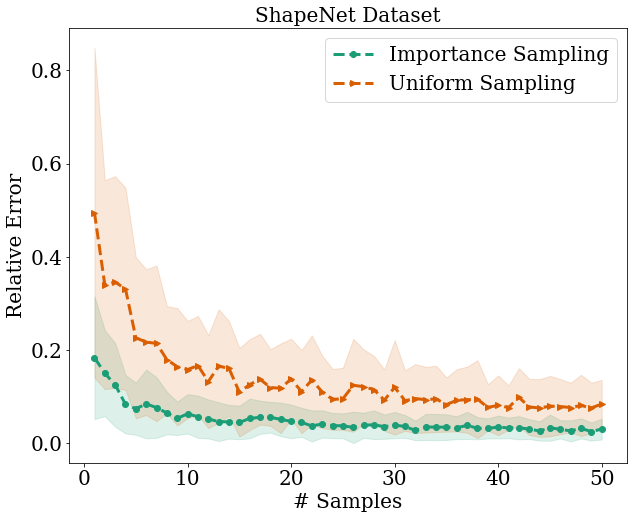

In [118]:
plt.figure(figsize=(10,8))
plt.rc('xtick', labelsize='x-small')
plt.rc('ytick', labelsize='x-small')
plt.rc('font', **{'size':'25'})
plt.rc('font', family='serif')
color = cm.Dark2(np.linspace(0, 1, 6))
plt.plot(samples, samples_approx.mean(axis=0) ,  'o--', c=color[0], label="Importance Sampling", linewidth=3)
plt.plot(samples, uniform_approx.mean(axis=0) ,  '>--', c=color[1], label="Uniform Sampling", linewidth=3)
plt.fill_between(samples, samples_approx.mean(axis=0) +  samples_approx.std(axis=0), samples_approx.mean(axis=0) -  samples_approx.std(axis=0), color=color[0], alpha=.15)
plt.fill_between(samples, uniform_approx.mean(axis=0) +  uniform_approx.std(axis=0), uniform_approx.mean(axis=0) -  uniform_approx.std(axis=0), color=color[1], alpha=.15)

plt.legend(fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.title('ShapeNet Dataset', fontsize=20)
plt.xlabel('# Samples', fontsize=20)
plt.ylabel('Relative Error', fontsize=20)
plt.savefig("shapenet_importance_vs_uniform.pdf", dpi=150, bbox_inches='tight')
plt.show()

# Federalist Papers

In [32]:
# Load point clouds (computed from W2V embeddings)
dataset_A = np.load('federalist/federalist_83.npy')
dataset_B = np.load('federalist/federalist_84.npy')
dataset = np.vstack((dataset_A, dataset_B))
print(dataset_A.shape, dataset_B.shape)
# Binary array which tracks which points belong with dataset A or B.
affiliation_array = np.hstack((np.zeros(len(dataset_A)), np.ones(len(dataset_B))))

(2586, 300) (1880, 300)


In [26]:
# Compute the true value
true_val = (distance.cdist(dataset_A, dataset_B, metric='cityblock').min(axis=1)).sum() + (distance.cdist(dataset_B, dataset_A, metric='cityblock').min(axis=1)).sum()
print(true_val)
%timeit (distance.cdist(dataset_A, dataset_B, metric='cityblock').min(axis=1)).sum() + (distance.cdist(dataset_B, dataset_A, metric='cityblock').min(axis=1)).sum()

75524.04506414756
1.31 s ± 7.84 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [80]:
# Get approximation values for D_a and D_b according to our algorithm
output = approx_chamfer_estimates(dataset, affiliation_array, 3, p=1)
prob_A = output[:len(dataset_A)]/output[:len(dataset_A)].sum()
prob_B = output[len(dataset_A):]/output[len(dataset_A):].sum()
print(output.sum()/true_val)

1.452065798638745


In [1]:
# Compare uniform sampling vs our importance sampling across a number of samples
samples = range(2, 51, 2)
rel_err_ours = np.zeros((len(samples), 50))
rel_err_uniform = np.zeros((len(samples), 50))
for i, s in enumerate(samples):
    for t in range(50):
        our_estimate = importance_sampling(dataset_A, dataset_B, prob_A, prob_B, s)
        rel_err_ours[i, t] = (abs(our_estimate-true_val)/true_val)
        uniform_estimate = importance_sampling(dataset_A, dataset_B, np.ones(len(dataset_A))/len(dataset_A),np.ones(len(dataset_B))/len(dataset_B), s)
        rel_err_uniform[i, t] = (abs(uniform_estimate-true_val)/true_val)

In [90]:
print(rel_err_ours.mean(axis=1))
print(rel_err_ours.std(axis=1))
print(rel_err_uniform.mean(axis=1))
print(rel_err_uniform.std(axis=1))

[0.05895406 0.04945074 0.03643574 0.02534176 0.02806373 0.02350407
 0.02065625 0.02259411 0.01861539 0.01986738 0.0170709  0.01597467
 0.02013374 0.01661971 0.01997019 0.01680481 0.01656074 0.01285813
 0.01501652 0.01516982 0.01410702 0.01312959 0.01293363 0.01343596
 0.01315095]
[0.0486619  0.03818843 0.02838175 0.02059665 0.02453742 0.01576227
 0.0133818  0.01501162 0.01428534 0.01395397 0.01357333 0.01269362
 0.01451036 0.01176457 0.01370141 0.0114263  0.01176628 0.00793604
 0.01009819 0.0110737  0.01137551 0.00963264 0.00970617 0.00975848
 0.01029257]
[0.49989789 0.31110372 0.2779571  0.17783702 0.18261053 0.19335437
 0.15957212 0.15898957 0.1470584  0.15983875 0.12942493 0.12017308
 0.13507421 0.1274634  0.11514611 0.13214736 0.12010876 0.11140693
 0.11180986 0.08527975 0.10195599 0.06613687 0.0847498  0.06668176
 0.09869551]
[0.34797789 0.23778802 0.19951013 0.14021174 0.12927713 0.15361592
 0.13530728 0.12318385 0.11509809 0.11920404 0.08755438 0.07325074
 0.09702273 0.09042444 

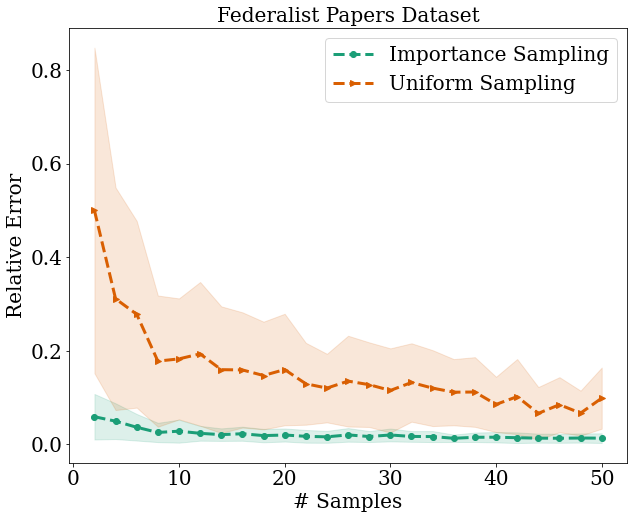

In [83]:
plt.figure(figsize=(10,8))
plt.rc('xtick', labelsize='x-small')
plt.rc('ytick', labelsize='x-small')
plt.rc('font', **{'size':'25'})
plt.rc('font', family='serif')
color = cm.Dark2(np.linspace(0, 1, 6))
plt.plot(samples, rel_err_ours.mean(axis=1) ,  'o--', c=color[0], label="Importance Sampling", linewidth=3)
plt.plot(samples, rel_err_uniform.mean(axis=1) ,  '>--', c=color[1], label="Uniform Sampling", linewidth=3)
plt.fill_between(samples,  rel_err_ours.mean(axis=1) +   rel_err_ours.std(axis=1),  rel_err_ours.mean(axis=1) -   rel_err_ours.std(axis=1), color=color[0], alpha=.15)
plt.fill_between(samples,  rel_err_uniform.mean(axis=1) +   rel_err_uniform.std(axis=1),  rel_err_uniform.mean(axis=1) -   rel_err_uniform.std(axis=1), color=color[1], alpha=.15)

plt.legend(fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.title('Federalist Papers Dataset', fontsize=20)
plt.xlabel('# Samples', fontsize=20)
plt.ylabel('Relative Error', fontsize=20)
plt.savefig("federalist_importance_vs_uniform.pdf", dpi=150, bbox_inches='tight')
plt.show()